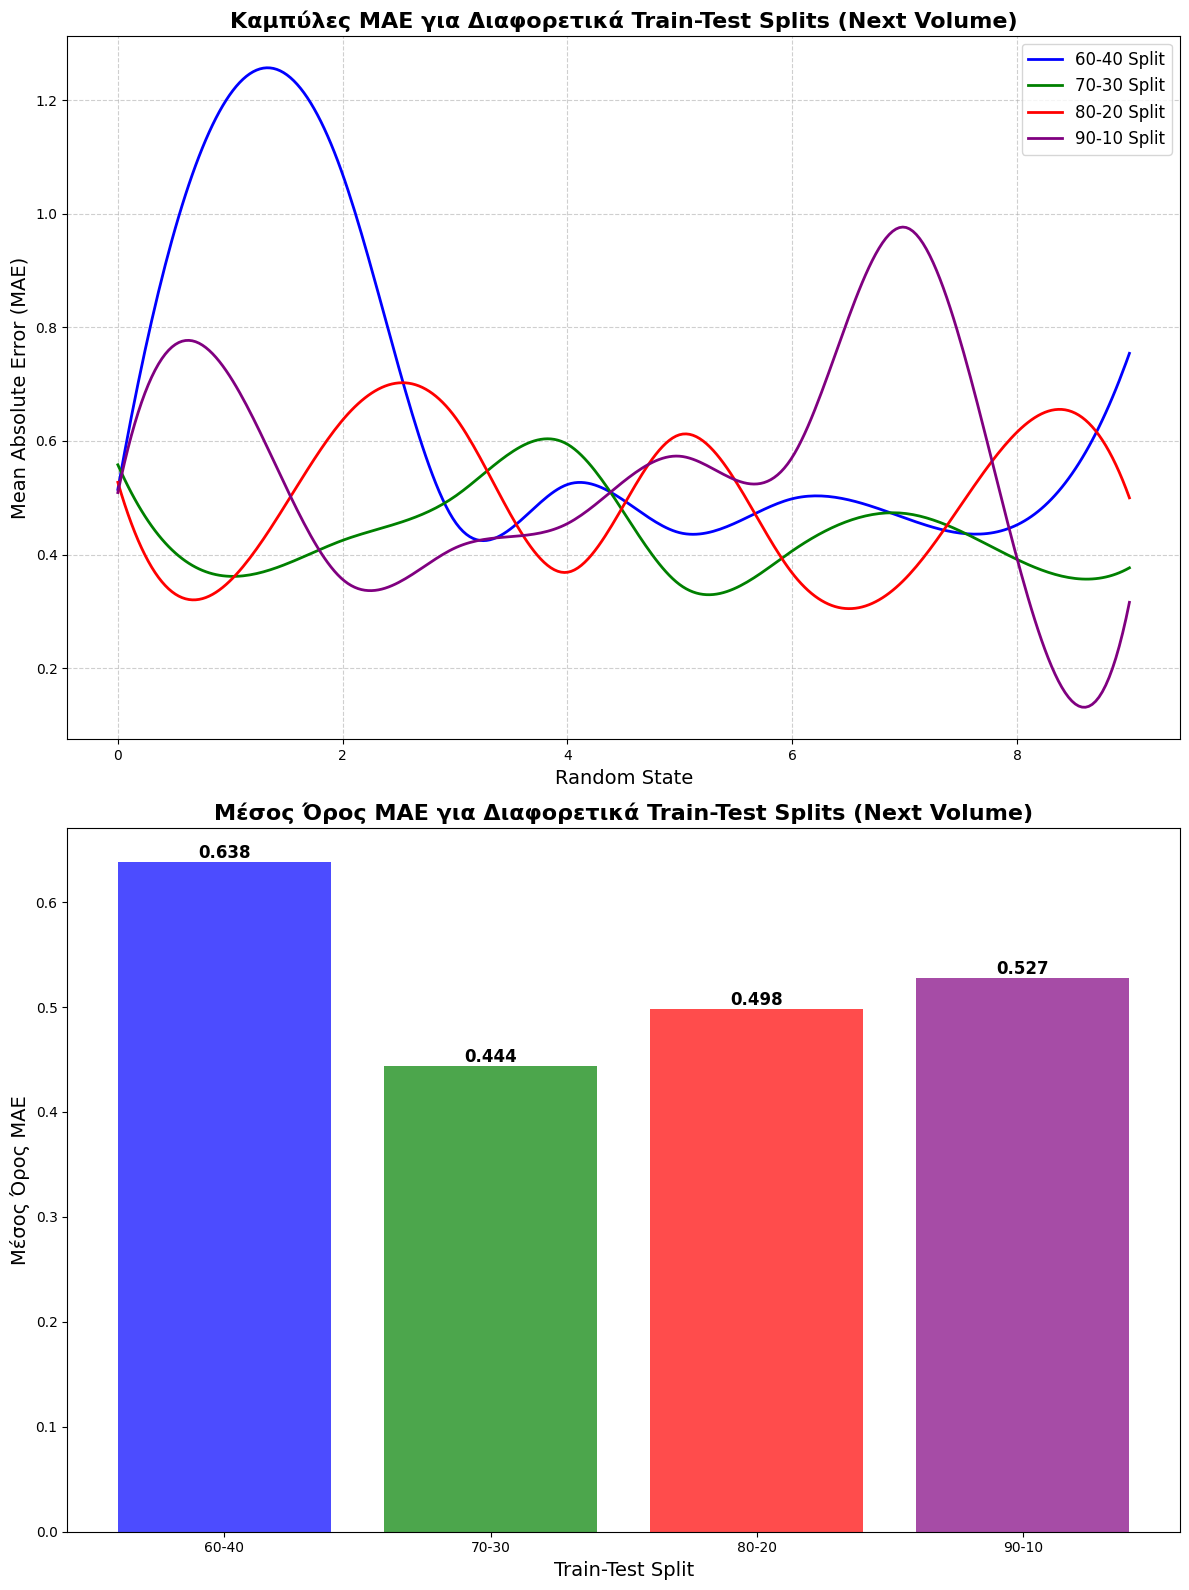

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import make_interp_spline

# Δεδομένα για τα splits
random_states = np.array(list(range(10)))

mae_60_40 =np.array([
    0.5148169333951714, 1.2105370469333474, 1.0691214771421098,
    0.4577686471161659, 0.5233800619000769, 0.438477893001748,
    0.4982683909936338, 0.46459710590950704, 0.45231456756238747,
    0.7542446597483969
])
mae_70_30 = np.array([
    0.5580876970590468, 0.3617486925253778, 0.42511867415663246,
    0.5024807797676571, 0.5942136615036427, 0.34704339082747604,
    0.406466966928954, 0.47251834195501563, 0.3914328153541613,
    0.3767294473071273
])
mae_80_20 = np.array([
    0.5271833531593745, 0.354179879347621, 0.6368850150981056,
    0.6421929054088337, 0.368890109078338, 0.611124231190491,
    0.3674995937456716, 0.35642108625374613, 0.6155641998765039,
    0.49992037232495556
])
mae_90_10 = np.array([
    0.5092120923589716, 0.7128169842406521, 0.3562681826718871,
    0.4117224407507363, 0.4545769074085445, 0.573175639001999,
    0.5713779944018429, 0.9762699640360171, 0.39327716626126735,
    0.3159776814285794
])

# Υπολογισμός μέσου όρου για κάθε split
mean_mae = [
    mae_60_40.mean(),
    mae_70_30.mean(),
    mae_80_20.mean(),
    mae_90_10.mean()
]

splits = ["60-40", "70-30", "80-20", "90-10"]

# Δημιουργία λείων καμπυλών με Spline Interpolation
x_smooth = np.linspace(random_states.min(), random_states.max(), 300)

mae_60_40_smooth = make_interp_spline(random_states, mae_60_40)(x_smooth)
mae_70_30_smooth = make_interp_spline(random_states, mae_70_30)(x_smooth)
mae_80_20_smooth = make_interp_spline(random_states, mae_80_20)(x_smooth)
mae_90_10_smooth = make_interp_spline(random_states, mae_90_10)(x_smooth)

# Δημιουργία γραφικής παράστασης
fig, axes = plt.subplots(2, 1, figsize=(12, 16))

# Πρώτο γράφημα: Καμπύλες MAE
axes[0].plot(x_smooth, mae_60_40_smooth, color='blue', label='60-40 Split', linewidth=2)
axes[0].plot(x_smooth, mae_70_30_smooth, color='green', label='70-30 Split', linewidth=2)
axes[0].plot(x_smooth, mae_80_20_smooth, color='red', label='80-20 Split', linewidth=2)
axes[0].plot(x_smooth, mae_90_10_smooth, color='purple', label='90-10 Split', linewidth=2)

axes[0].set_title('Καμπύλες MAE για Διαφορετικά Train-Test Splits (Next Volume)', fontsize=16, fontweight='bold')
axes[0].set_xlabel('Random State', fontsize=14)
axes[0].set_ylabel('Mean Absolute Error (MAE)', fontsize=14)
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend(fontsize=12, loc='upper right')

# Δεύτερο γράφημα: Bar Chart Μέσων Όρων MAE
bars = axes[1].bar(splits, mean_mae, color=['blue', 'green', 'red', 'purple'], alpha=0.7)

axes[1].set_title('Μέσος Όρος MAE για Διαφορετικά Train-Test Splits (Next Volume)', fontsize=16, fontweight='bold')
axes[1].set_xlabel('Train-Test Split', fontsize=14)
axes[1].set_ylabel('Μέσος Όρος MAE', fontsize=14)

# Προσθήκη τιμών πάνω από τις μπάρες
for bar, value in zip(bars, mean_mae):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{value:.3f}',
        ha='center', va='bottom', fontsize=12, fontweight='bold'
    )

plt.tight_layout()
plt.show()
